# 05 · Ventanas móviles y cobertura

Se estiman soportes locales sobre la misma traza sintética. Ventanas y centros se fijan antes de calcular; el solapamiento hace dependientes las estimaciones. Se usa la API Python y GeoPandas.

In [1]:
from pathlib import Path
import os
import sys
import time
import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Image
from shapely.geometry import LineString, box
from pyproj import CRS

started_wall, started_cpu = time.perf_counter(), time.process_time()
repository = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/musa").is_dir())
sys.path.insert(0, str(repository / "src"))
sys.path.insert(0, str(repository / "scripts"))
from musa import MUSA, ScalingOptions, assess_lineament_scaling, write_scaling_reports
crs = CRS.from_proj4("+proj=eqc +R=6371000 +units=m +no_defs +type=crs")
lines = [LineString([(1000, 1500), (9000, 6500)])]
domain = box(0, 0, 10000, 10000)
scales = np.geomspace(10, 1000, 16)
model = MUSA.from_line_geometries(lines, domain, crs, q_values=[0, 1, 2])
output = Path(os.environ.get("MUSA_NOTEBOOK_OUTPUT_ROOT", repository / "outputs/notebooks")) / "05_moving_windows"
output.mkdir(parents=True, exist_ok=True)
def save_figure(figure, name):
    target = output / (name + ".png")
    figure.savefig(target, dpi=120, bbox_inches="tight")
    display(Image(filename=str(target)))
    plt.close(figure)
print("Synthetic inputs; unlocated model metres. Outputs:", output.name)


Synthetic inputs; unlocated model metres. Outputs: 05_moving_windows


## Ejecutar ventanas

Se fijan ventanas de 4000 m, paso 4000 m y cuatro divisores internos. La salida conserva cobertura y motivos para todas las ventanas y q.

,center_id,window_m,q,coverage,dq,accepted,reason
0,0,4000.0,0.0,1.00,0.860288,True,accepted
1,0,4000.0,1.0,1.00,0.938591,False,dominant_box
2,0,4000.0,2.0,1.00,0.974104,False,dominant_box
3,1,4000.0,0.0,1.00,NaN,False,insufficient_support
4,1,4000.0,1.0,1.00,NaN,False,insufficient_support
5,1,4000.0,2.0,1.00,NaN,False,insufficient_support
6,2,4000.0,0.0,0.50,NaN,False,low_coverage
7,2,4000.0,1.0,0.50,NaN,False,low_coverage
8,2,4000.0,2.0,0.50,NaN,False,low_coverage
9,3,4000.0,0.0,1.00,NaN,False,insufficient_support


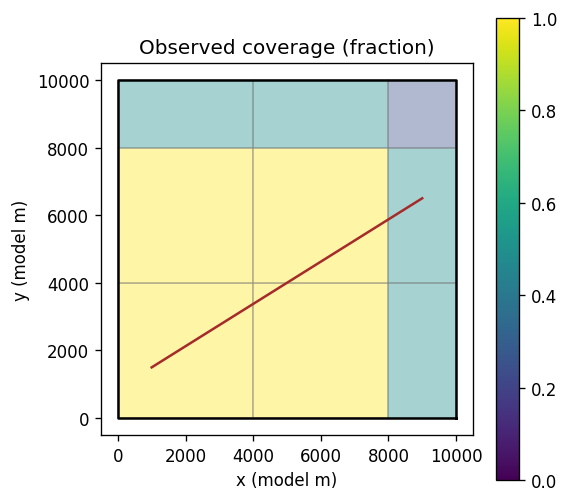

In [2]:
from musa.moving import analyze_moving_windows
windows, nodes, configuration = analyze_moving_windows(model, [4000], 4000, divisors=(2,4,8,16), q_values=[0,1,2])
assert len(windows) > 0 and windows.center_id.nunique() == 9
assert (windows.coverage < .8).any()
display(windows[["center_id", "window_m", "q", "coverage", "dq", "accepted", "reason"]])
windows.drop(columns="geometry").to_csv(output / "windows.csv", index=False)
nodes.drop(columns="geometry").to_csv(output / "nodes.csv", index=False)
(output / "configuration.json").write_text(json.dumps(configuration, indent=2), encoding="utf-8")
figure, ax = plt.subplots(figsize=(5, 5))
windows.drop_duplicates("center_id").plot(ax=ax, column="coverage", vmin=0, vmax=1, legend=True, alpha=.4, edgecolor="gray")
ax.plot(*lines[0].xy, color="brown")
ax.plot(*domain.exterior.xy, color="black")
ax.set(xlabel="x (model m)", ylabel="y (model m)", title="Observed coverage (fraction)")
save_figure(figure, "window_coverage")

## Conservar abstenciones

Una ventana con menos del 80 % observado conserva su estado y sus motivos. Las curvas locales canónicas y ponderadas tienen contratos separados. El paso cambia el solapamiento, mientras la resolución procede de la cartografía.

In [3]:
low = windows[windows.coverage < .8]
assert not low.accepted.any()
display(low[["center_id", "coverage", "q", "reason"]].head(9))
print("Unique supports:", windows.center_id.nunique(), "rows:", len(windows))

,center_id,coverage,q,reason
6,2,0.5,0.0,low_coverage
7,2,0.5,1.0,low_coverage
8,2,0.5,2.0,low_coverage
15,5,0.5,0.0,low_coverage
16,5,0.5,1.0,low_coverage
17,5,0.5,2.0,low_coverage
18,6,0.5,0.0,low_coverage
19,6,0.5,1.0,low_coverage
20,6,0.5,2.0,low_coverage


Unique supports: 9 rows: 27


In [4]:
metrics = dict(wall_seconds=time.perf_counter()-started_wall,
               cpu_seconds_kernel=time.process_time()-started_cpu)
(output / "execution.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")
print(json.dumps(metrics))


{"wall_seconds": 2.2649248999996416, "cpu_seconds_kernel": 2.234375}
